# Milestone 3: Exploratory Data Analysis
This notebook explores distributions, trends and seasonality, and differences across stores, counties, products and customer segments.


## Step 1: Import relevant libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')

BLUE, ORANGE, GREY = '#2a6f97', '#e07a1f', '#9aa5b1'   # one main colour, one highlight colour
def short(x, divisor, suffix):
    v = x / divisor
    return f'{v:,.0f}{suffix}' if abs(v - round(v)) < 1e-6 else f'{v:,.1f}{suffix}'   # decimals only when needed

millions = FuncFormatter(lambda x, _: short(x, 1e6, 'M'))
thousands = FuncFormatter(lambda x, _: short(x, 1e3, 'K'))
START, END = pd.Timestamp('2022-01-01'), pd.Timestamp('2025-09-30')

## Step 2: Loading the cleaned datasets

In [2]:
CLEAN_DIR = '../data/clean'

stores = pd.read_csv(f'{CLEAN_DIR}/stores.csv', parse_dates=['opening_date'])
products = pd.read_csv(f'{CLEAN_DIR}/products.csv')
promotions = pd.read_csv(f'{CLEAN_DIR}/promotions.csv', parse_dates=['start_date', 'end_date'])
customers = pd.read_csv(f'{CLEAN_DIR}/customers.csv', dtype={'phone': str}, parse_dates=['signup_date'])
transactions = pd.read_csv(f'{CLEAN_DIR}/transactions.csv', parse_dates=['transaction_date'])
knbs = pd.read_csv(f'{CLEAN_DIR}/knbs.csv')

for name, df in [('stores', stores), ('products', products), ('promotions', promotions),
                 ('customers', customers), ('transactions', transactions), ('knbs', knbs)]:
    print(f'{name:13s} {df.shape[0]:>8,} rows x {df.shape[1]} columns')

stores              40 rows x 10 columns
products           300 rows x 10 columns
promotions          12 rows x 7 columns
customers        5,000 rows x 15 columns
transactions   250,000 rows x 23 columns
knbs                47 rows x 11 columns


## Step 3: Building the analysis tables
- The clean tables are joined into three views, so each question can be answered at the right level:
- `sales`: one row per sale line, with product and store details attached
- `invoices`: one row per basket
- `cust_sum`: one row per customer who has bought (revenue, number of invoices, recency)

In [3]:
sales = (transactions
         .merge(products[['product_id', 'product_name', 'category', 'subcategory', 'brand', 'unit_cost_kes']],
                on='product_id', how='left')
         .merge(stores[['store_id', 'store_name', 'county', 'store_type']], on='store_id', how='left'))

invoices = (sales.groupby('invoice_no')
            .agg(invoice_date=('transaction_date', 'first'), store_id=('store_id', 'first'),
                 customer_id=('customer_id', 'first'), payment_method=('payment_method', 'first'),
                 channel=('channel', 'first'), lines=('transaction_id', 'count'),
                 units=('quantity', 'sum'), value=('line_total_kes', 'sum'))
            .reset_index())

cust_sum = (sales.dropna(subset=['customer_id']).groupby('customer_id')
            .agg(revenue=('line_total_kes', 'sum'), invoices=('invoice_no', 'nunique'),
                 first_purchase=('transaction_date', 'min'), last_purchase=('transaction_date', 'max'))
            .reset_index())
cust_sum['recency_days'] = (END - cust_sum['last_purchase']).dt.days
cust_sum = cust_sum.merge(customers[['customer_id', 'age', 'age_band', 'gender', 'loyalty_member',
                                     'preferred_payment', 'county', 'tenure_days']], on='customer_id')

print('sales', sales.shape, '| invoices', invoices.shape, '| customers who bought', cust_sum.shape)

sales (250000, 31) | invoices (88647, 9) | customers who bought (4605, 13)


## Step 4: Overview: the headline numbers

In [4]:
kpis = pd.Series({
    'Period': f"{sales['transaction_date'].min().date()} to {sales['transaction_date'].max().date()}",
    'Net revenue (KES million)': round(sales['line_total_kes'].sum() / 1e6, 1),
    'Invoices (baskets)': f"{invoices.shape[0]:,}",
    'Sale lines': f"{sales.shape[0]:,}",
    'Customers who bought': f"{cust_sum.shape[0]:,} of {customers.shape[0]:,}",
    'Average invoice value (KES)': round(invoices['value'].mean()),
    'Median invoice value (KES)': round(invoices['value'].median()),
    'Average lines per invoice': round(invoices['lines'].mean(), 2),
    'Returns, share of lines': f"{sales['is_return'].mean():.1%}",
    'Walk-in (no customer), share of revenue': f"{sales.loc[sales['is_walkin'], 'line_total_kes'].sum() / sales['line_total_kes'].sum():.1%}",
    'Online, share of invoices': f"{(invoices['channel'] == 'Online').mean():.1%}",
}, name='Value')
kpis.to_frame()

,Value
Period,2022-01-01 to 2025-09-30
Net revenue (KES million),202.90
Invoices (baskets),"88,647"
Sale lines,"250,000"
Customers who bought,"4,605 of 5,000"
Average invoice value (KES),2289
Median invoice value (KES),1769
Average lines per invoice,2.82
"Returns, share of lines",0.5%
"Walk-in (no customer), share of revenue",3.6%


## Step 5: Distributions

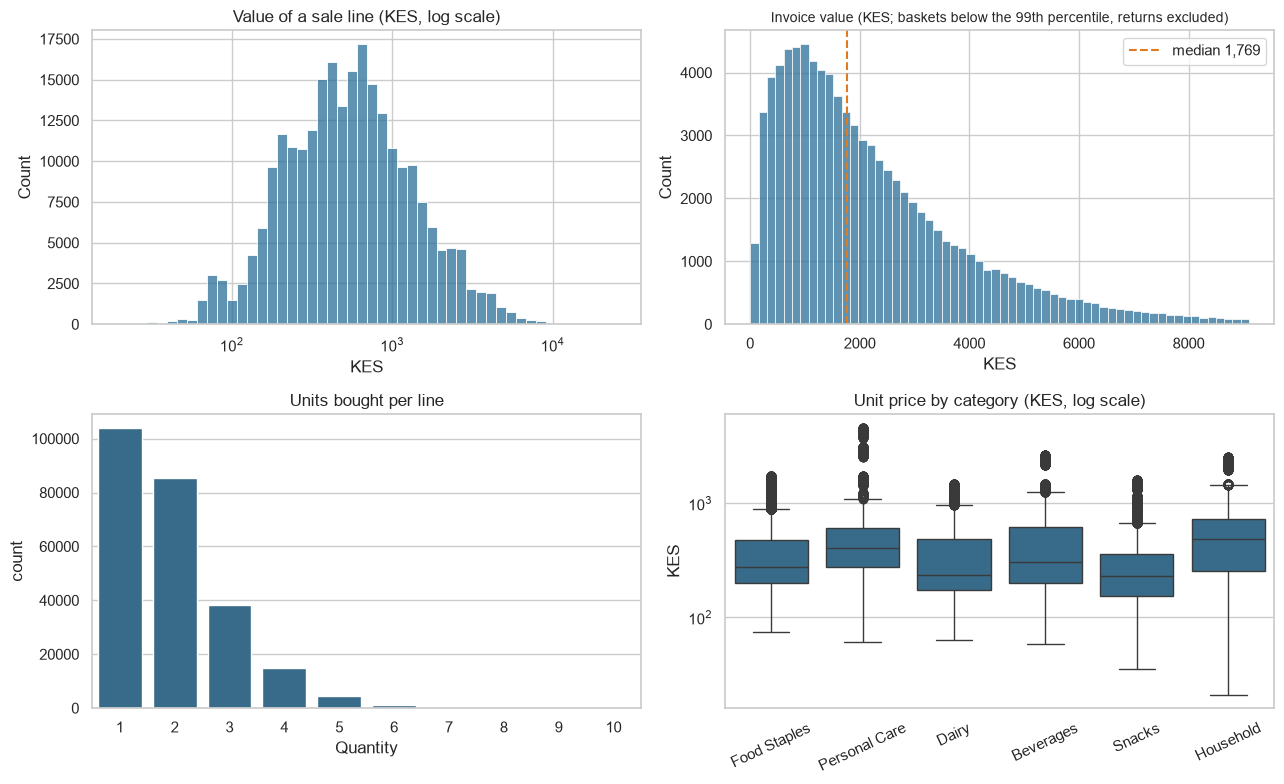

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

sns.histplot(sales.loc[~sales['is_return'], 'line_total_kes'], log_scale=True, bins=50, color=BLUE, ax=ax[0, 0])
ax[0, 0].set_title('Value of a sale line (KES, log scale)'); ax[0, 0].set_xlabel('KES')

v = invoices['value']
sns.histplot(v[(v > 0) & (v < v.quantile(0.99))], bins=60, color=BLUE, ax=ax[0, 1])
ax[0, 1].axvline(v.median(), color=ORANGE, ls='--', label=f'median {v.median():,.0f}')
ax[0, 1].legend(); ax[0, 1].set_title('Invoice value (KES; baskets below the 99th percentile, returns excluded)', fontsize=10)
ax[0, 1].set_xlabel('KES')

sns.countplot(x=sales.loc[~sales['is_return'], 'quantity'], color=BLUE, ax=ax[1, 0])
ax[1, 0].set_title('Units bought per line'); ax[1, 0].set_xlabel('Quantity')

sns.boxplot(data=sales, x='category', y='unit_price_kes', color=BLUE, ax=ax[1, 1])
ax[1, 1].set_yscale('log'); ax[1, 1].set_title('Unit price by category (KES, log scale)')
ax[1, 1].set_xlabel(''); ax[1, 1].set_ylabel('KES'); ax[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout(); plt.show()

### Observation: 
- Sales are mostly small, with a median line value of KES 535 and 76% of lines containing one or two units. 
- A few expensive items raise the average invoice to KES 2,289, above the median of KES 1,769. 
- Household and Personal Care have higher median unit prices, so categories should be compared by revenue rather than units sold.

## Step 6: Trends over time and seasonality

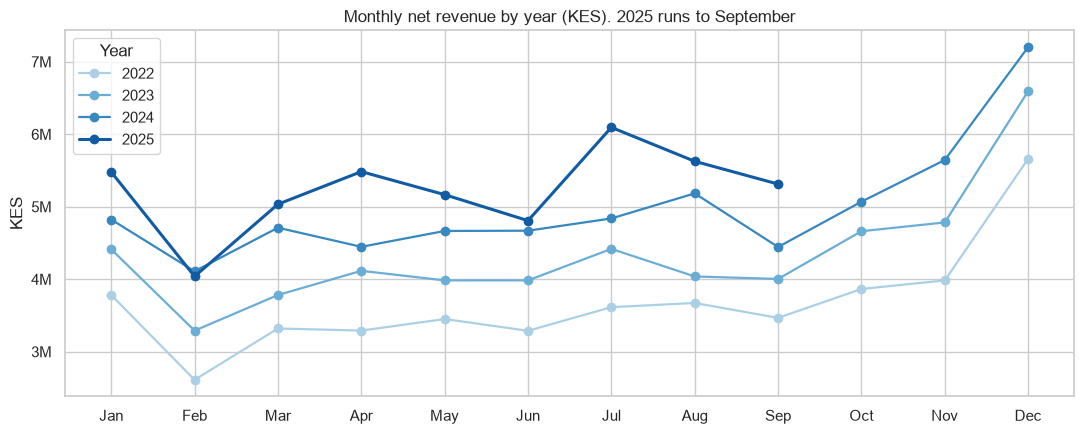

In [6]:
monthly = sales.groupby(['year', 'month'])['line_total_kes'].sum().unstack(0)
fig, ax = plt.subplots(figsize=(11, 4.5))
for yr, colour in zip(monthly.columns, sns.color_palette('Blues', 5)[1:]):
    ax.plot(monthly.index, monthly[yr], marker='o', color=colour, label=str(yr), lw=2.2 if yr == 2025 else 1.6)
ax.yaxis.set_major_formatter(millions); ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_title('Monthly net revenue by year (KES). 2025 runs to September'); ax.set_ylabel('KES'); ax.legend(title='Year')
plt.tight_layout(); plt.show()

__is the business growing?__ 
- Comparing the same months (Jan to Sep) in each year, because 2025 only has nine months.

In [7]:
ytd = (sales[sales['month'] <= 9].groupby('year')
       .agg(revenue=('line_total_kes', 'sum'), units=('quantity', 'sum'), invoices=('invoice_no', 'nunique')))
ytd['revenue_growth_%'] = ytd['revenue'].pct_change() * 100
ytd['units_growth_%'] = ytd['units'].pct_change() * 100
ytd['invoices_growth_%'] = ytd['invoices'].pct_change() * 100
ytd

,revenue,units,invoices,revenue_growth_%,units_growth_%,invoices_growth_%
year,,,,,,
2022,"30,499,638.60",78549,14645,NaN,NaN,NaN
2023,"36,031,291.62",87870,16244,18.14,11.87,10.92
2024,"41,894,584.78",95781,17670,16.27,9.00,8.78
2025,"47,047,296.90",102985,19025,12.30,7.52,7.67


### Observation: 
- Revenue continues to grow, but growth is slowing, from 18.1% in 2023 to 12.3% in 2025. 
- Units sold and invoices are also growing more slowly. 
- Monthly sales follow a consistent seasonal pattern, supporting future forecasting.

__seasonality: month, day of week and payday__

- The month index compares each month's average daily revenue with that year's average, then averages across years, so it is not distorted by growth.

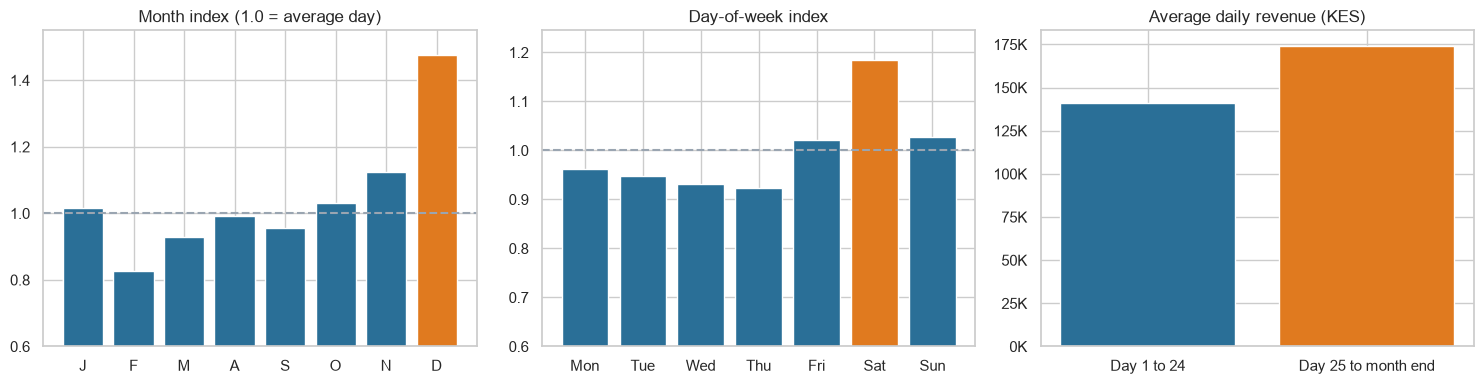

December index: 1.48 | February index: 0.83
Saturday index: 1.19
Payday period uplift: 23.5%


In [8]:
daily = sales.groupby('transaction_date')['line_total_kes'].sum().rename('revenue').to_frame()
daily['year'], daily['month'] = daily.index.year, daily.index.month
daily['dow'], daily['payday'] = daily.index.dayofweek, daily.index.day >= 25
daily['month_index'] = daily['revenue'] / daily.groupby('year')['revenue'].transform('mean')

month_index = daily.groupby('month')['month_index'].mean()
dow_index = daily.groupby('dow')['revenue'].mean() / daily['revenue'].mean()
payday = daily.groupby('payday')['revenue'].mean()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
cols = [ORANGE if v == month_index.max() else BLUE for v in month_index]
ax[0].bar(['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'], month_index.values, color=cols)
ax[0].axhline(1, color=GREY, ls='--'); ax[0].set_title('Month index (1.0 = average day)')
cols = [ORANGE if v == dow_index.max() else BLUE for v in dow_index]
ax[1].bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], dow_index.values, color=cols)
ax[1].axhline(1, color=GREY, ls='--'); ax[1].set_title('Day-of-week index')
ax[2].bar(['Day 1 to 24', 'Day 25 to month end'], payday.values, color=[BLUE, ORANGE])
ax[2].yaxis.set_major_formatter(thousands); ax[2].set_title('Average daily revenue (KES)')
for a in ax[:2]: a.set_ylim(0.6, None)
plt.tight_layout(); plt.show()

print('December index:', round(month_index[12], 2), '| February index:', round(month_index[2], 2))
print('Saturday index:', round(dow_index[5], 2))
print('Payday period uplift:', f'{payday[True] / payday[False] - 1:.1%}')

### Observation: 
- Revenue continues to grow, but growth is slowing, from 18.1% in 2023 to 12.3% in 2025. 
- Units sold and invoices are also growing more slowly. 
- Monthly sales follow a consistent seasonal pattern, supporting future forecasting.

## Step 7: Stores and counties

- New stores open during the period, so stores are compared on revenue per day open, not total revenue.

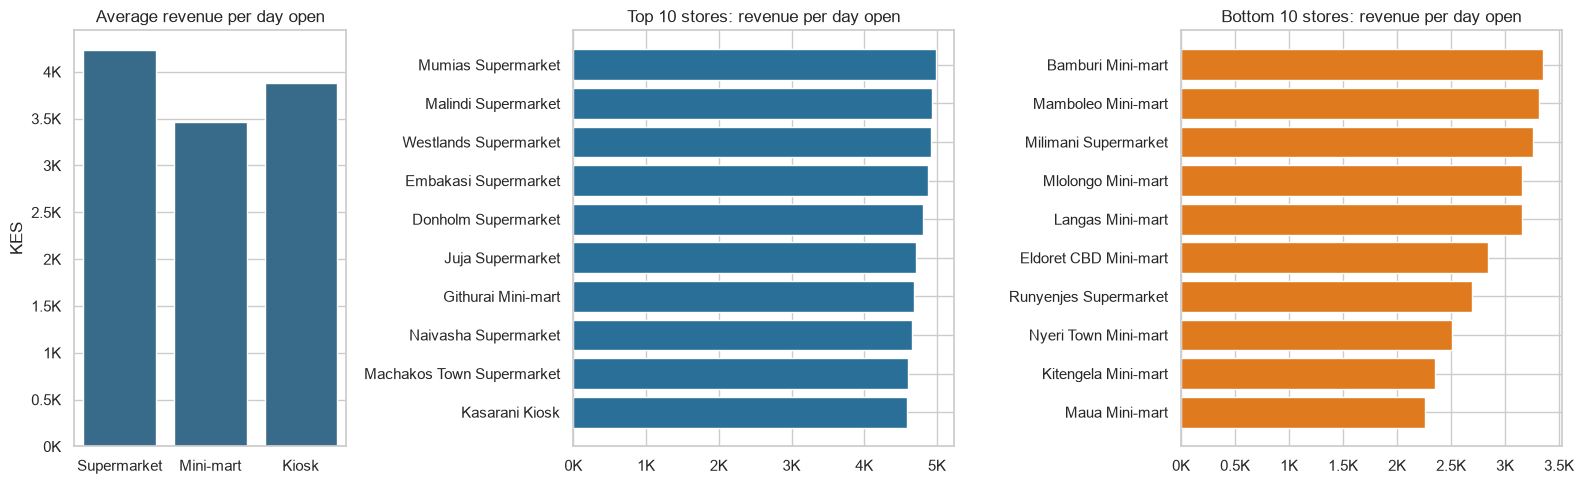

Best vs worst store (revenue per day open): 4,984 vs 2,257 KES


,mean,count
store_type,,
Kiosk,"3,882.00",5
Mini-mart,"3,465.00",16
Supermarket,"4,230.00",19


In [9]:

# Store performance analysis
# Calculate total revenue for each store
store_rev = (
    sales.groupby('store_id')['line_total_kes'].sum()  # Add up sales revenue for each store
    .rename('revenue')                                 # Name the result 'revenue'
    .reset_index()                                     # Convert store_id from index to a column
    .merge(stores, on='store_id')                      # Add store details, such as name and type
)

# Calculate how many days each store was open during the analysis period
# If a store opened before START, use START as its first analysis date
store_rev['days_open'] = (
    END - store_rev['opening_date'].clip(lower=START)
).dt.days + 1

# Calculate average revenue earned per day each store was open
store_rev['revenue_per_day'] = (
    store_rev['revenue'] / store_rev['days_open']
)

# Rank stores from highest to lowest revenue per day
ranked = store_rev.sort_values('revenue_per_day', ascending=False)

# Create three charts in one figure
# The first chart compares store types; the other two show individual stores
fig, ax = plt.subplots(
    1, 3, figsize=(16, 5),
    gridspec_kw={'width_ratios': [1, 1.4, 1.4]}
)

# Chart 1: Compare average daily revenue across store types
sns.barplot(
    data=store_rev,
    x='store_type',
    y='revenue_per_day',
    order=['Supermarket', 'Mini-mart', 'Kiosk'],  # Set the display order
    errorbar=None,
    color=BLUE,
    ax=ax[0]
)

# Format the vertical axis as thousands of Kenyan shillings
ax[0].yaxis.set_major_formatter(thousands)
ax[0].set_title('Average revenue per day open')
ax[0].set_xlabel('')  # Remove the x-axis label
ax[0].set_ylabel('KES')

# Select the ten highest- and ten lowest-performing stores
top = ranked.head(10)
bottom = ranked.tail(10)

# Chart 2: Display the ten best-performing stores
# [::-1] reverses the order so the bars display neatly from top to bottom
ax[1].barh(
    top['store_name'][::-1],
    top['revenue_per_day'][::-1],
    color=BLUE
)
ax[1].xaxis.set_major_formatter(thousands)
ax[1].set_title('Top 10 stores: revenue per day open')

# Chart 3: Display the ten lowest-performing stores
ax[2].barh(
    bottom['store_name'][::-1],
    bottom['revenue_per_day'][::-1],
    color=ORANGE
)
ax[2].xaxis.set_major_formatter(thousands)
ax[2].set_title('Bottom 10 stores: revenue per day open')

# Adjust spacing so chart labels do not overlap, then display the charts
plt.tight_layout()
plt.show()

# Print the daily revenue of the best and worst-performing stores
print(
    'Best vs worst store (revenue per day open):',
    f"{ranked['revenue_per_day'].iloc[0]:,.0f} vs "
    f"{ranked['revenue_per_day'].iloc[-1]:,.0f} KES"
)

# Summarize average daily revenue and number of stores in each store type
# mean = average revenue per day; count = number of stores
store_rev.groupby('store_type')['revenue_per_day'].agg(
    ['mean', 'count']
).round(0)


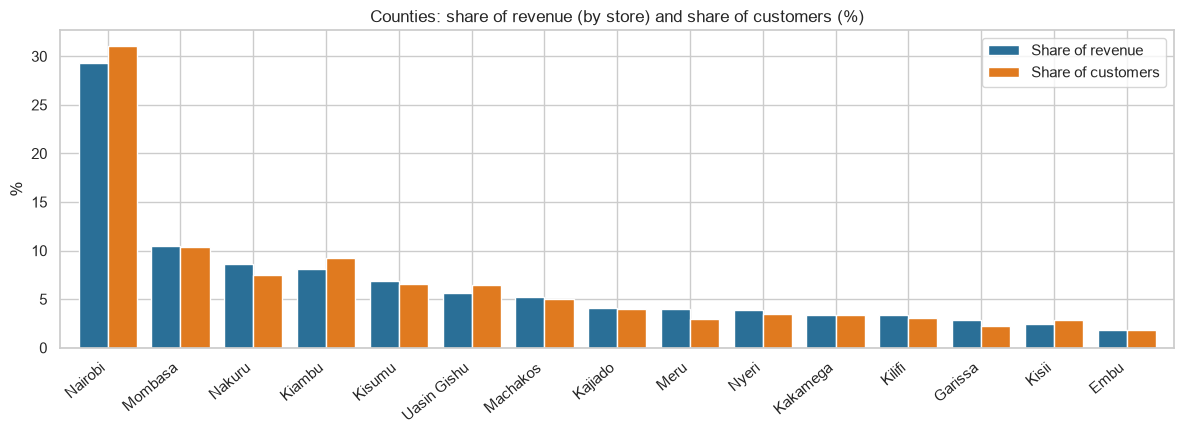

county,Nairobi,Mombasa,Nakuru,Kiambu,Kisumu,Uasin Gishu,Machakos,Kajiado,Meru,Nyeri,Kakamega,Kilifi,Garissa,Kisii,Embu
Share of revenue,0.29,0.10,0.09,0.08,0.07,0.06,0.05,0.04,0.04,0.04,0.03,0.03,0.03,0.03,0.02
Share of customers,0.31,0.10,0.07,0.09,0.07,0.06,0.05,0.04,0.03,0.04,0.03,0.03,0.02,0.03,0.02


In [10]:
#Comparing revenue and customers across counties

# Calculate total sales revenue associated with each county
# This assumes sales contains a 'county' column identifying the store's county
county_rev = sales.groupby('county')['line_total_kes'].sum()

# Count the customers recorded in each county
county_cust = customers['county'].value_counts()

# Calculate each county's percentage share of total revenue and customers
compare = pd.DataFrame({
    'Share of revenue': county_rev / county_rev.sum(),
    'Share of customers': county_cust / county_cust.sum()
}).sort_values(
    'Share of revenue', ascending=False  # Rank counties by revenue share
)

# Plot the two shares side by side for each county
# Multiply by 100 to convert proportions into percentages
ax = (compare * 100).plot(
    kind='bar',
    color=[BLUE, ORANGE],
    figsize=(12, 4.5),
    width=0.8
)

# Add a title and axis labels
ax.set_title(
    'Counties: share of revenue (by store) and share of customers (%)'
)
ax.set_ylabel('%')
ax.set_xlabel('')

# Rotate county names so they are easier to read
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

# Display the underlying comparison table
# .round(3) rounds the proportions to three decimal places
# .T transposes the table so the measures appear as rows
compare.round(3).T


### Observation: 
- Store performance is relatively consistent, with supermarkets leading at KES 4,230 daily and the best-performing store earning about 2.2 times the lowest. 
- Store type alone does not explain performance differences. 
- By county, revenue broadly matches customer share, although Nakuru slightly overperforms and Kiambu underperforms, warranting further investigation.

# Comparing county retail performance with KNBS population data

In [11]:
knbs = knbs.rename(columns={
    'County': 'county_name',
    'Total_Population19': 'population_2019',
    'Households': 'households',
    'Population Density': 'density_per_km2'
})

In [12]:
# Standardize county names for matching
def county_key(name):
    k = str(name).lower().strip()
    for word in [' city', ' county']:
        k = k.replace(word, '')
    return k.replace('-', ' ').replace('_', ' ').replace('/', ' ').strip()

knbs['county_key'] = knbs['county_name'].map(county_key)

The 15 counties represented in the retail data account for 49% of the population across all 47 KNBS counties.


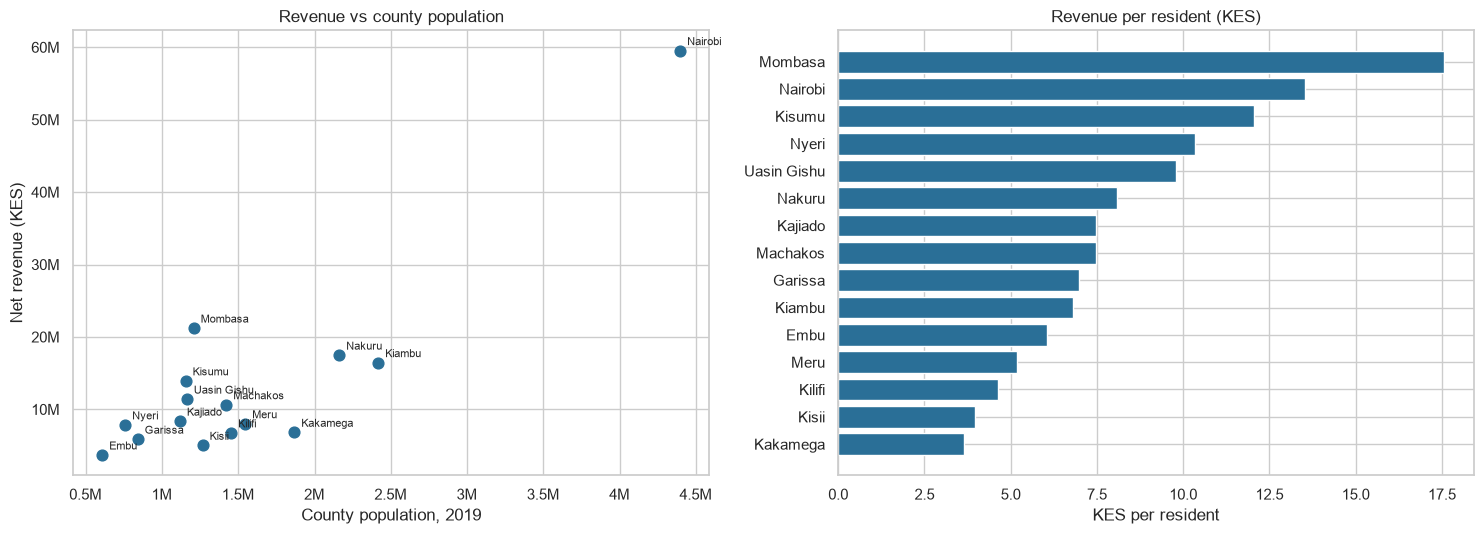

Rank correlation between county population and revenue: 0.51
Highest revenue per resident: Mombasa (KES 18); lowest: Kakamega (KES 4)


,county,population_2019,stores,residents_per_store,revenue,revenue_per_resident,customers_per_100k
3,Kakamega,"1,867,579.00",1,"1,867,579.00","6,822,721.50",3.70,8.90
5,Kilifi,"1,453,787.00",1,"1,453,787.00","6,745,931.10",4.60,10.40
6,Kisii,"1,266,860.00",1,"1,266,860.00","5,024,937.50",4.00,11.40
1,Garissa,"841,353.00",1,"841,353.00","5,868,763.30",7.00,13.10
4,Kiambu,"2,417,735.00",3,"805,911.70","16,436,878.50",6.80,19.20
9,Meru,"1,545,714.00",2,"772,857.00","7,995,580.60",5.20,9.70
12,Nakuru,"2,162,202.00",3,"720,734.00","17,471,817.50",8.10,17.20
8,Machakos,"1,421,932.00",2,"710,966.00","10,623,349.90",7.50,17.80
0,Embu,"608,599.00",1,"608,599.00","3,689,595.10",6.10,15.30
2,Kajiado,"1,117,840.00",2,"558,920.00","8,357,864.50",7.50,17.90


In [13]:
# Create a county-level table containing revenue, stores, and customers
cty = pd.DataFrame({
    'revenue': county_rev,                      # Total revenue per county
    'stores': stores.groupby('county').size(),  # Number of stores per county
    'customers': county_cust                   # Number of customers per county
}).rename_axis('county').reset_index()

# Standardize county names to match the KNBS dataset
cty['county_key'] = cty['county'].map(county_key)

# Merge county data with KNBS population, households, and population density
cty = cty.merge(
    knbs[['county_key', 'population_2019', 'households', 'density_per_km2']],
    on='county_key',
    how='left'
)

# Check that every county matches a KNBS record
missing = cty.loc[cty['population_2019'].isna(), 'county'].tolist()
assert not missing, f'No KNBS match for {missing}. Check the county names.'

# Convert KNBS figures to numeric values
for col in ['population_2019', 'households', 'density_per_km2']:
    cty[col] = cty[col].astype(float)

# Calculate revenue per resident in each county
cty['revenue_per_resident'] = cty['revenue'] / cty['population_2019']

# Estimate the number of residents per store
cty['residents_per_store'] = cty['population_2019'] / cty['stores']

# Calculate recorded customers per 100,000 residents
cty['customers_per_100k'] = (
    cty['customers'] / cty['population_2019'] * 100000
)

# Calculate the share of Kenya's 2019 population covered by these counties
covered = (
    cty['population_2019'].sum()
    / knbs['population_2019'].astype(float).sum()
)

print(
    f'The {len(cty)} counties represented in the retail data account for '
    f'{covered:.0%} of the population across all {len(knbs)} KNBS counties.'
)

# Create two charts side by side
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

# Chart 1: Compare county population with total retail revenue
ax[0].scatter(
    cty['population_2019'], cty['revenue'], color=BLUE, s=60
)

# Label each point with its county name
for _, r in cty.iterrows():
    ax[0].annotate(
        r['county'],
        (r['population_2019'], r['revenue']),
        fontsize=8,
        xytext=(5, 4),
        textcoords='offset points'
    )

# Format the axes and add chart labels
ax[0].xaxis.set_major_formatter(millions)
ax[0].yaxis.set_major_formatter(millions)
ax[0].set_xlabel('County population, 2019')
ax[0].set_ylabel('Net revenue (KES)')
ax[0].set_title('Revenue vs county population')

# Sort counties by revenue per resident
ordered = cty.sort_values('revenue_per_resident')

# Chart 2: Compare revenue per resident across counties
ax[1].barh(
    ordered['county'],
    ordered['revenue_per_resident'],
    color=BLUE
)
ax[1].set_title('Revenue per resident (KES)')
ax[1].set_xlabel('KES per resident')

# Adjust chart spacing and display the charts
plt.tight_layout()
plt.show()

# Calculate the Spearman rank correlation between population and revenue
rho = cty['population_2019'].corr(
    cty['revenue'], method='spearman'
)

# Identify the counties with the highest and lowest revenue per resident
best = ordered.iloc[-1]
worst = ordered.iloc[0]

# Print the correlation and highest/lowest revenue per resident
print(f'Rank correlation between county population and revenue: {rho:.2f}')
print(
    f"Highest revenue per resident: {best['county']} "
    f"(KES {best['revenue_per_resident']:,.0f}); "
    f"lowest: {worst['county']} "
    f"(KES {worst['revenue_per_resident']:,.0f})"
)

# Display county population, store coverage, and performance measures
# Counties with the most residents per store appear first
display(
    cty.sort_values('residents_per_store', ascending=False)[[
        'county',
        'population_2019',
        'stores',
        'residents_per_store',
        'revenue',
        'revenue_per_resident',
        'customers_per_100k'
    ]].round(1)
)


### Observation: 
- Nairobi leads in total revenue, reflecting its large population and stronger retail presence. 
- However, the relationship between population and revenue is moderate (Spearman correlation = 0.51), suggesting that population alone does not explain county performance. 
- Mombasa records the highest revenue per resident (KES 17.60), while Kakamega records the lowest (KES 3.70).

## Step 8: Products and categories

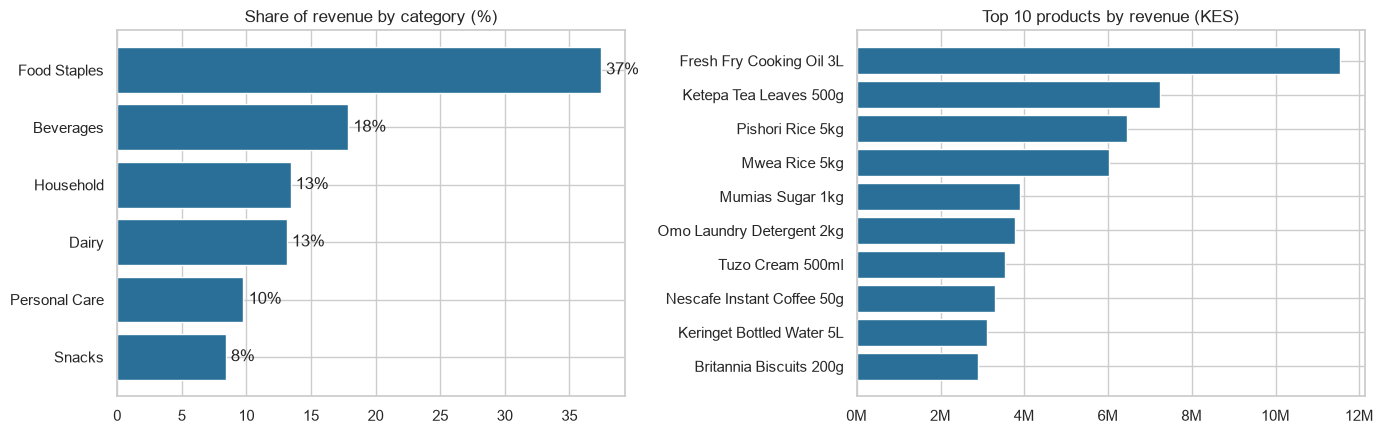

Top 30 of 300 products make 46% of revenue


In [14]:
cat_rev = sales.groupby('category')['line_total_kes'].sum().sort_values()
prod_rev = sales.groupby('product_name')['line_total_kes'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(cat_rev.index, cat_rev.values / cat_rev.sum() * 100, color=BLUE)
for i, v in enumerate(cat_rev.values / cat_rev.sum() * 100):
    ax[0].text(v + 0.4, i, f'{v:.0f}%', va='center')
ax[0].set_title('Share of revenue by category (%)')
top10 = prod_rev.head(10)[::-1]
ax[1].barh(top10.index, top10.values, color=BLUE); ax[1].xaxis.set_major_formatter(millions)
ax[1].set_title('Top 10 products by revenue (KES)')
plt.tight_layout(); plt.show()
print(f'Top 30 of {len(prod_rev)} products make {prod_rev.head(30).sum() / prod_rev.sum():.0%} of revenue')

## Step 9: Customer segments

- Only customers who bought are included (walk-in sales have no customer record).

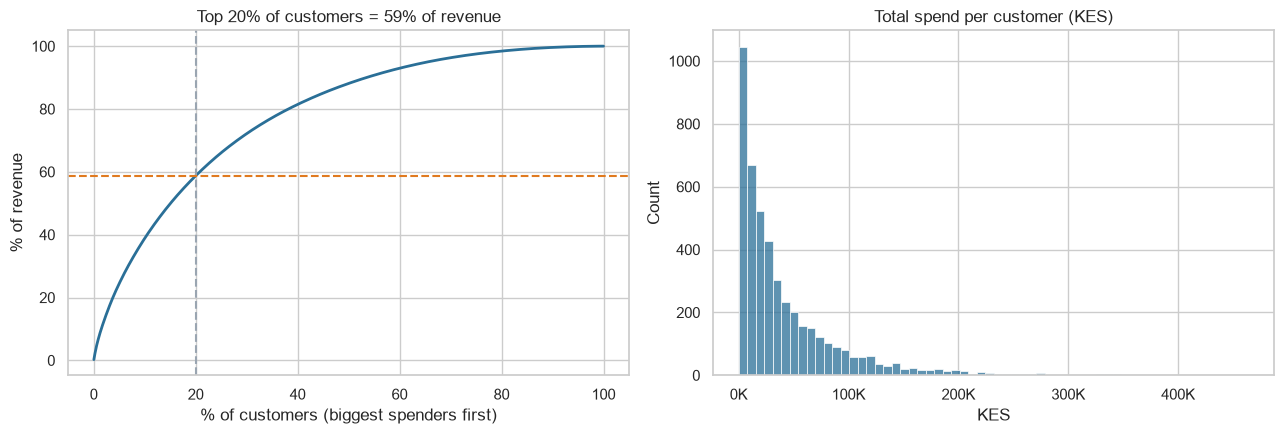

In [15]:
rev_sorted = cust_sum['revenue'].sort_values(ascending=False).reset_index(drop=True)
cum = rev_sorted.cumsum() / rev_sorted.sum() * 100
share_x = (np.arange(1, len(rev_sorted) + 1) / len(rev_sorted)) * 100
top20 = cum[int(len(rev_sorted) * 0.2) - 1]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(share_x, cum, color=BLUE, lw=2)
ax[0].axvline(20, color=GREY, ls='--'); ax[0].axhline(top20, color=ORANGE, ls='--')
ax[0].set_title(f'Top 20% of customers = {top20:.0f}% of revenue')
ax[0].set_xlabel('% of customers (biggest spenders first)'); ax[0].set_ylabel('% of revenue')
sns.histplot(cust_sum['revenue'], bins=60, color=BLUE, ax=ax[1])
ax[1].xaxis.set_major_formatter(thousands); ax[1].set_title('Total spend per customer (KES)'); ax[1].set_xlabel('KES')
plt.tight_layout(); plt.show()

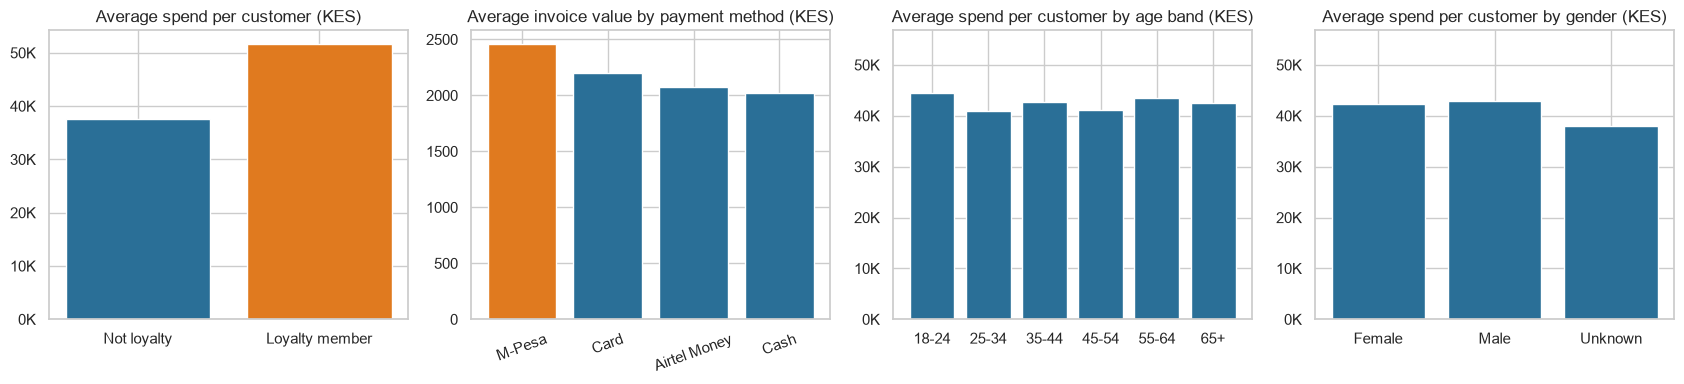

Loyalty members:  35% of buyers, 43% of customer revenue
Payment method mix (share of invoices):
payment_method
M-Pesa         57.20
Cash           28.90
Card            9.30
Airtel Money    4.60


,mean,median,count
payment_method,,,
Airtel Money,"2,075.00","1,598.00",4056
Card,"2,203.00","1,701.00",8245
Cash,"2,020.00","1,514.00",25641
M-Pesa,"2,457.00","1,934.00",50705


In [16]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4))

loy = cust_sum.groupby('loyalty_member')['revenue'].mean()
ax[0].bar(['Not loyalty', 'Loyalty member'], loy.values, color=[BLUE, ORANGE]); ax[0].yaxis.set_major_formatter(thousands)
ax[0].set_title('Average spend per customer (KES)')

pay = invoices.groupby('payment_method')['value'].mean().sort_values(ascending=False)
ax[1].bar(pay.index, pay.values, color=[ORANGE if p == 'M-Pesa' else BLUE for p in pay.index])
ax[1].set_title('Average invoice value by payment method (KES)'); ax[1].tick_params(axis='x', rotation=20)

age = cust_sum.groupby('age_band')['revenue'].mean().drop('Unknown', errors='ignore')
ax[2].bar(age.index, age.values, color=BLUE); ax[2].yaxis.set_major_formatter(thousands)
ax[2].set_ylim(0, loy.max() * 1.1); ax[2].set_title('Average spend per customer by age band (KES)')

gen = cust_sum.groupby('gender')['revenue'].mean()
ax[3].bar(gen.index, gen.values, color=BLUE); ax[3].yaxis.set_major_formatter(thousands)
ax[3].set_ylim(0, loy.max() * 1.1); ax[3].set_title('Average spend per customer by gender (KES)')
plt.tight_layout(); plt.show()

print('Loyalty members: ', f"{cust_sum['loyalty_member'].mean():.0%} of buyers, "
      f"{cust_sum.loc[cust_sum['loyalty_member'], 'revenue'].sum() / cust_sum['revenue'].sum():.0%} of customer revenue")
print('Payment method mix (share of invoices):'); print((invoices['payment_method'].value_counts(normalize=True) * 100).round(1).to_string())
invoices.groupby('payment_method')['value'].agg(['mean', 'median', 'count']).round(0)

In [17]:
mix = (invoices.assign(year=invoices['invoice_date'].dt.year).groupby(['year', 'payment_method']).size()
       .unstack().pipe(lambda d: d.div(d.sum(axis=1), axis=0)) * 100)
mix.round(1)

payment_method,Airtel Money,Card,Cash,M-Pesa
year,,,,
2022,5.10,9.10,28.80,57.00
2023,4.60,9.10,29.70,56.60
2024,4.20,9.50,28.80,57.50
2025,4.40,9.50,28.30,57.80


### Observation: 
- Spending is concentrated among top customers, while loyalty members spend 38% more on average than non-members. 
- M-Pesa dominates payments, with average invoice values 22% higher than cash. 
- Age and gender show minimal spending differences; Milestone 5 will formally test the loyalty and payment gaps.

__how long since customers last bought?__ 

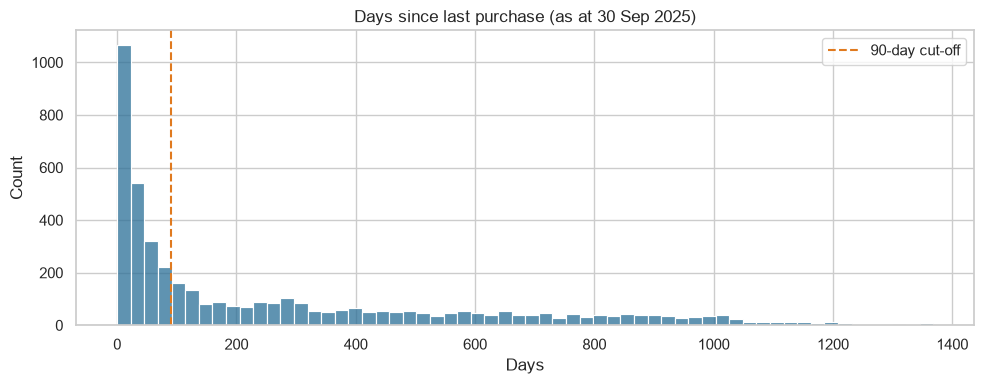

Inactive for more than 90 days: 53.4% of customers who bought
Median days since last purchase: 112
Customers who never bought: 395


In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(cust_sum['recency_days'], bins=60, color=BLUE, ax=ax)
ax.axvline(90, color=ORANGE, ls='--', label='90-day cut-off')
ax.set_title('Days since last purchase (as at 30 Sep 2025)'); ax.set_xlabel('Days'); ax.legend()
plt.tight_layout(); plt.show()
print(f"Inactive for more than 90 days: {(cust_sum['recency_days'] > 90).mean():.1%} of customers who bought")
print('Median days since last purchase:', int(cust_sum['recency_days'].median()))
print('Customers who never bought:', len(customers) - len(cust_sum))

## Step 10: Promotions (initial review)

- Compare average daily chain revenue during each promotion with the preceding 28 days. 
- PR01 is excluded due to insufficient prior data. Seasonal effects will be controlled for in the formal statistical tests.

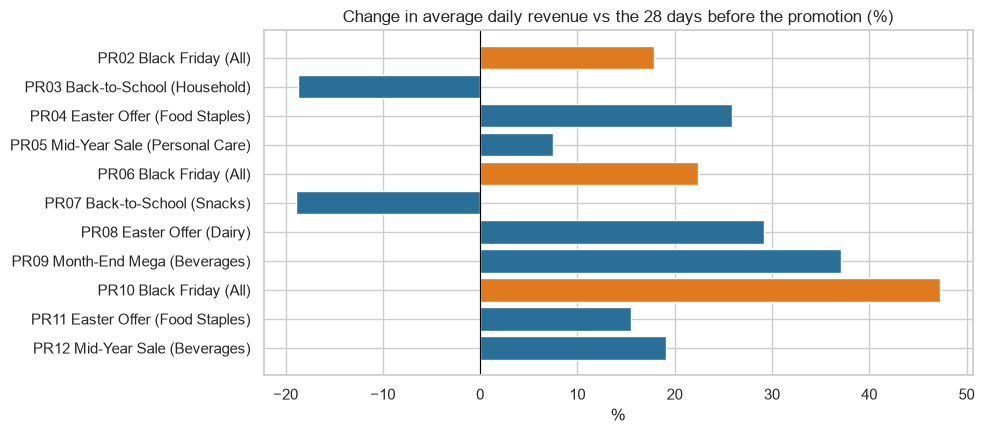

,promo,discount_pct,avg_daily_before,avg_daily_during,lift_pct
0,PR02 Black Friday (All),25,"132,894.30","156,600.90",17.80
1,PR03 Back-to-School (Household),12,"177,799.40","144,518.20",-18.70
2,PR04 Easter Offer (Food Staples),10,"119,578.80","150,490.80",25.90
3,PR05 Mid-Year Sale (Personal Care),15,"131,283.70","141,069.90",7.50
4,PR06 Black Friday (All),30,"157,027.10","192,184.20",22.40
5,PR07 Back-to-School (Snacks),12,"208,784.60","169,277.80",-18.90
6,PR08 Easter Offer (Dairy),10,"144,200.80","186,216.10",29.10
7,PR09 Month-End Mega (Beverages),8,"157,911.50","216,429.80",37.10
8,PR10 Black Friday (All),25,"171,550.90","252,707.50",47.30
9,PR11 Easter Offer (Food Staples),10,"169,142.60","195,396.80",15.50


In [19]:
daily_rev = daily['revenue']
rows = []
for _, p in promotions.iterrows():
    prior_start = p['start_date'] - pd.Timedelta(days=28)
    if prior_start < START:
        continue
    during = daily_rev[p['start_date']:p['end_date']].mean()
    before = daily_rev[prior_start:p['start_date'] - pd.Timedelta(days=1)].mean()
    rows.append(dict(promo=f"{p['promo_id']} {p['promo_name']} ({p['category_targeted']})", discount_pct=p['discount_pct'],
                     avg_daily_before=before, avg_daily_during=during, lift_pct=(during / before - 1) * 100))
lift = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [ORANGE if 'Black Friday' in p else BLUE for p in lift['promo']]
ax.barh(lift['promo'][::-1], lift['lift_pct'][::-1], color=colors[::-1]); ax.axvline(0, color='black', lw=0.8)
ax.set_title('Change in average daily revenue vs the 28 days before the promotion (%)'); ax.set_xlabel('%')
plt.tight_layout(); plt.show()
lift.round(1)

### Observation: 
- Promotions show mixed results, with Black Friday and other campaigns increasing revenue by 8% to 47%, while Back-to-School promotions show declines of about 19%.

## Step 11: Relationships between customer measures

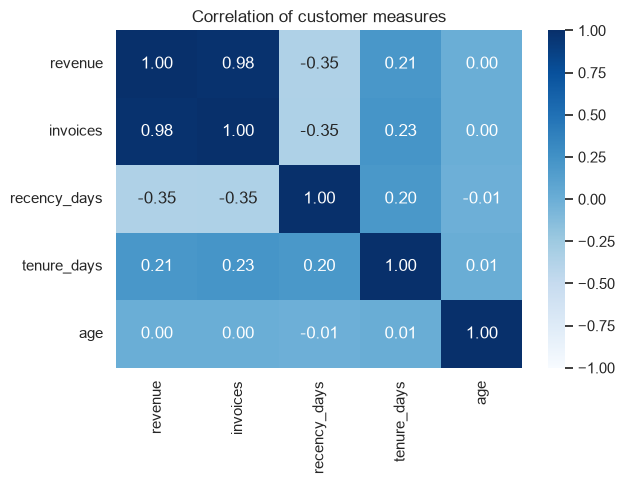

In [20]:
corr = cust_sum[['revenue', 'invoices', 'recency_days', 'tenure_days', 'age']].astype(float).corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1)
plt.title('Correlation of customer measures'); plt.tight_layout(); plt.show()

## Step 12: The five findings that matter most

**1. Growth is solid but slowing.** January to September revenue grew 18% (2023), 16% (2024) and 12% (2025), while units sold grew only 12%, 9% and 7.5%. About 5 to 7 points of each year's growth is price, not volume.

**2. Sales follow a strong calendar.** December is 1.48 times an average day and February only 0.83, Saturdays run 19% above average, and days 25 to month end bring 23.5% more revenue per day. Stock, staffing and any forecast should be built around these patterns.

**3. Revenue is concentrated.** Nairobi brings 29% of revenue, Food Staples 37%, the top 30 of 300 products 46%, and the top 20% of customers 59%. Stores are more even: the best earns about 2.2 times the worst per day open.

**4. M-Pesa and loyalty customers are the high-value groups.** M-Pesa is 57% of invoices and its invoices are 22% larger than cash. Loyalty members are 35% of buyers but 43% of customer revenue and spend 38% more per head. Age and gender make almost no difference. (These gaps are tested formally in Milestone 5.)

**5. Over half of customers are inactive.** 53% of customers who bought have not bought in 90 days (median 112 days since last purchase). Spend and number of invoices are almost the same measure (0.98 correlation). Promotions show mixed lifts (-19% to +47%) that are distorted by seasonality, so they need a controlled test.